<a href="https://colab.research.google.com/github/riturajtigga12-netizen/ybi-foundation-internship-project/blob/main/Admission_chances.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)



# Step 2: Load Dataset


data_path = "data/Admission Chance.csv"

admission = pd.read_csv('https://github.com/ybifoundation/Dataset/raw/main/Admission%20Chance.csv')


print("Dataset loaded successfully!")
print()


# ============================================
# Step 3: Display Dataset
# ============================================

print("First 5 records:")
print(admission.head())

print("\nDataset shape:")
print(admission.shape)

print("\nDataset information:")
print(admission.info())

print("\nStatistical summary:")
print(admission.describe())


Dataset loaded successfully!

First 5 records:
   Serial No  GRE Score  TOEFL Score  University Rating   SOP  LOR   CGPA  \
0          1        337          118                  4   4.5   4.5  9.65   
1          2        324          107                  4   4.0   4.5  8.87   
2          3        316          104                  3   3.0   3.5  8.00   
3          4        322          110                  3   3.5   2.5  8.67   
4          5        314          103                  2   2.0   3.0  8.21   

   Research  Chance of Admit   
0         1              0.92  
1         1              0.76  
2         1              0.72  
3         1              0.80  
4         0              0.65  

Dataset shape:
(400, 9)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Serial No          400 non-null    int64  
 1 

In [2]:
admission.columns = admission.columns.str.strip()

print("\nColumn names:")
print(admission.columns)





Column names:
Index(['Serial No', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP',
       'LOR', 'CGPA', 'Research', 'Chance of Admit'],
      dtype='object')


In [3]:
# ============================================
# Step 5: Check Missing Values
# ============================================

print("\nMissing values:")
print(admission.isnull().sum())




Missing values:
Serial No            0
GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             0
Chance of Admit      0
dtype: int64


In [4]:

# Step 6: Define X and y

X = admission.drop(
    ["Serial No", "Chance of Admit"],
    axis=1
)

y = admission["Chance of Admit"]


print("\nFeatures:")
print(X.columns)

print("\nTarget:")
print(y.name)



Features:
Index(['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA',
       'Research'],
      dtype='object')

Target:
Chance of Admit


In [5]:
# ============================================
# Step 7: Split Dataset
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=2529
)

print("\nTraining data:", X_train.shape)
print("Testing data:", X_test.shape)





Training data: (280, 7)
Testing data: (120, 7)


In [6]:
# ============================================
# Step 8: Create Model
# ============================================

model = LinearRegression()

# ============================================
# Step 9: Train Model
# ============================================

model.fit(X_train, y_train)

print("\nModel trained successfully!")





Model trained successfully!


In [7]:

# Step 10: Display Model Parameters
# ============================================

print("\nModel Intercept:")
print(model.intercept_)

print("\nModel Coefficients:")
print(model.coef_)



Model Intercept:
-1.2831244932033998

Model Coefficients:
[ 0.00204057  0.00287273  0.00566887 -0.00380559  0.01973175  0.11314449
  0.02061553]


In [8]:
# ============================================
# Step 11: Make Predictions
# ============================================

y_pred = model.predict(X_test)

print("\nPredictions:")
print(y_pred)




Predictions:
[0.71426327 0.72534136 0.69677103 0.66566584 0.57483872 0.93087527
 0.93701113 0.72361387 0.81130158 0.62223963 0.59629648 0.80084072
 0.52537944 0.79174558 0.84064992 0.66429594 0.65136589 0.66990687
 0.75794085 0.86072023 0.66088101 0.85570763 0.84777425 0.95033179
 0.68750762 0.65907671 0.65279623 0.5709259  0.55895645 0.57990205
 0.54497918 0.7570717  0.69682571 0.77286067 0.64320811 0.5183554
 0.43816818 0.84654064 0.90398354 0.80517781 0.72218971 0.72882587
 0.68145136 0.88592237 0.77208852 0.78778085 0.95526121 0.88586486
 0.59980416 0.50690214 0.59947098 0.63380406 0.82841217 0.44911724
 0.71068577 0.77335748 0.68851557 0.64486026 0.85537724 0.65517768
 0.65046031 0.90818978 0.63422429 0.68658606 0.72150268 0.69030545
 0.59381287 0.93813035 0.58997351 0.91542587 0.59283415 0.93351713
 0.59478751 0.71380389 0.54346237 0.84710913 0.6084418  0.7257337
 0.67545704 0.81387503 0.70259527 0.88600461 0.67084016 0.53064995
 0.77790726 0.65780713 0.78970635 0.54709634 0.779

In [9]:
# ============================================
# Step 12: Evaluate Model
# ============================================

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

mape = mean_absolute_percentage_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)


print("\n========== MODEL PERFORMANCE ==========")

print("Mean Absolute Error:", mae)

print("Mean Squared Error:", mse)

print("Root Mean Squared Error:", rmse)

print("Mean Absolute Percentage Error:", mape)

print("R2 Score:", r2)


========== MODEL PERFORMANCE ==========
Mean Absolute Error: 0.04400128934232651
Mean Squared Error: 0.004038263715495693
Root Mean Squared Error: 0.06354733444839125
Mean Absolute Percentage Error: 0.07575278864605438
R2 Score: 0.8066078856630293


In [10]:
# ============================================
# Step 13: Save Predictions
# ============================================
import os

# Create the outputs directory if it doesn't exist
os.makedirs("outputs", exist_ok=True)

results = pd.DataFrame({
    "Actual Chance": y_test.values,
    "Predicted Chance": y_pred
})

results.to_csv(
    "outputs/predictions.csv",
    index=False
)

print("\nOutputs directory verified and predictions saved successfully!")


Outputs directory verified and predictions saved successfully!


In [11]:
# ============================================
# Step 14: Save Model
# ============================================
import os
import joblib

# Create the models directory if it doesn't exist
os.makedirs("models", exist_ok=True)

joblib.dump(
    model,
    "models/admission_model.pkl"
)

print("Model saved successfully in 'models/' directory!")

Model saved successfully in 'models/' directory!


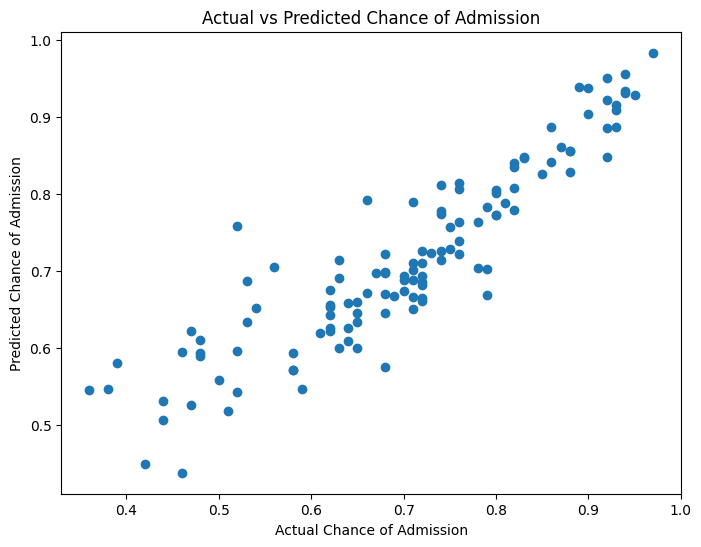

In [12]:
# ============================================
# Step 15: Visualization
# ============================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred
)

plt.xlabel("Actual Chance of Admission")

plt.ylabel("Predicted Chance of Admission")

plt.title(
    "Actual vs Predicted Chance of Admission"
)

plt.show()

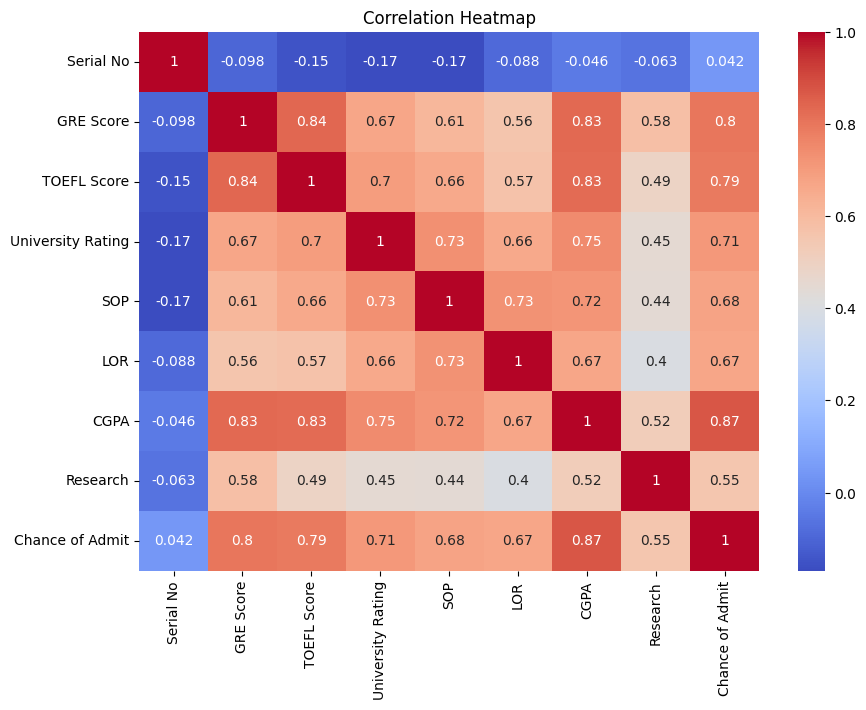


Project completed successfully!


In [13]:
# ============================================
# Step 16: Correlation Heatmap
# ============================================

plt.figure(figsize=(10, 7))

sns.heatmap(
    admission.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

print("\nProject completed successfully!")